# Healthcare Insurance Analysis — Capstone 1

**Objective:** predict patients' hospitalization costs and identify the factors that drive them.

Data: `Hospitalisation details` (cost, hospital/city tier, state, children, date of birth), `Medical Examinations`
(BMI, HbA1c, heart issues, transplants, cancer history, surgeries, smoker) and `Names`.
The SQL tasks are in [`healthcare_insurance.sql`](healthcare_insurance.sql).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100
DATA = "../Dataset/Capstone _1/"
RANDOM_STATE = 42

## Week 1 — Data science
### 1. Collate the files

In [2]:
hosp = pd.read_csv(DATA + "Hospitalisation details.csv")
med = pd.read_csv(DATA + "Medical Examinations.csv")
names = pd.read_excel(DATA + "Names.xlsx")
for n, d in [("hospitalisation", hosp), ("medical", med), ("names", names)]:
    print(f"{n:16s} {d.shape}")
df = hosp.merge(med, on="Customer ID", how="inner").merge(names, on="Customer ID", how="inner")
print("Collated:", df.shape)
df.head()

hospitalisation  (2343, 9)
medical          (2335, 8)
names            (2335, 2)
Collated: (2335, 17)


,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992,Jul,9,0,563.84,tier - 2,tier - 3,R1013,17.58,4.51,No,No,No,1,No,"German, Mr. Aaron K"
1,Id2334,1992,Nov,30,0,570.62,tier - 2,tier - 1,R1013,17.60,4.39,No,No,No,1,No,"Rosendahl, Mr. Evan P"
2,Id2333,1993,Jun,30,0,600.00,tier - 2,tier - 1,R1013,16.47,6.35,No,No,Yes,1,No,"Albano, Ms. Julie"
3,Id2332,1992,Sep,13,0,604.54,tier - 3,tier - 3,R1013,17.70,6.28,No,No,No,1,No,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998,Jul,27,0,637.26,tier - 3,tier - 3,R1013,22.34,5.57,No,No,No,1,No,"Brietzke, Mr. Jordan"


### 2. Missing values

In [3]:
print("NaN values per column:\n", df.isna().sum())

NaN values per column:
 Customer ID               0
year                      0
month                     0
date                      0
children                  0
charges                   0
Hospital tier             0
City tier                 0
State ID                  0
BMI                       0
HBA1C                     0
Heart Issues              0
Any Transplants           0
Cancer history            0
NumberOfMajorSurgeries    0
smoker                    0
name                      0
dtype: int64


No `NaN`s — but missing data is hidden as the trivial value **`?`**.
### 3. Rows with trivial values (`?`)

In [4]:
trivial = (df == "?").any(axis=1)
print((df == "?").sum()[lambda s: s > 0])
print(f"\nRows containing '?': {trivial.sum()} of {len(df)} = {trivial.mean():.2%}")
df = df[~trivial].copy()
print("Rows after removal:", len(df))

year             2
month            3
Hospital tier    1
City tier        1
State ID         2
smoker           2
dtype: int64

Rows containing '?': 10 of 2335 = 0.43%
Rows after removal: 2325


Under 0.5% of rows contain `?` and they cannot be reliably imputed (IDs, dates, tiers), so these rows are **deleted**.

### 4. Nominal & ordinal categorical variables
* **Ordinal:** `Hospital tier`, `City tier` (`tier - 1` is best/most developed) → integers 1-3.
* **Binary nominal:** `Heart Issues`, `Any Transplants`, `Cancer history`, `smoker` → 0/1.
* `State ID` is nominal — handled in step 5.

In [5]:
for c in ["Hospital tier", "City tier"]:
    df[c] = df[c].str.extract(r"(\d)").astype(int)
for c in ["Heart Issues", "Any Transplants", "Cancer history", "smoker"]:
    df[c] = df[c].str.strip().str.lower().map({"yes": 1, "no": 0})
df[["Hospital tier", "City tier", "Heart Issues", "Any Transplants", "Cancer history", "smoker"]].describe().loc[["min", "max", "mean"]]

,Hospital tier,City tier,Heart Issues,Any Transplants,Cancer history,smoker
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000
mean,2.168172,2.025806,0.395699,0.061075,0.168172,0.209032


### 5. State ID dummies — only R1011, R1012, R1013
16 states are unevenly represented. Only the three large states get their own dummy; every other state falls into the
baseline group ("other states"), avoiding many tiny, insignificant predictors.

In [6]:
print(df["State ID"].value_counts().head(6))
for s in ["R1011", "R1012", "R1013"]:
    df[f"state_{s}"] = (df["State ID"] == s).astype(int)
df[["State ID", "state_R1011", "state_R1012", "state_R1013"]].sample(5, random_state=1)

State ID
R1013    609
R1011    574
R1012    572
R1024    159
R1026     84
R1021     70
Name: count, dtype: int64


,State ID,state_R1011,state_R1012,state_R1013
583,R1011,1,0,0
1361,R1026,0,0,0
50,R1013,0,0,1
1124,R1016,0,0,0
618,R1012,0,1,0


### 6. Clean `NumberOfMajorSurgeries`

In [7]:
print("Before:", df["NumberOfMajorSurgeries"].unique())
df["NumberOfMajorSurgeries"] = df["NumberOfMajorSurgeries"].replace("No major surgery", "0").astype(int)
print("After: ", sorted(df["NumberOfMajorSurgeries"].unique()))

Before: <StringArray>
['1', 'No major surgery', '2', '3']
Length: 4, dtype: str
After:  [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


### 7. Age from date of birth
Ages are computed relative to a fixed reference date so that results are reproducible.

In [8]:
REF_DATE = pd.Timestamp("2026-10-26")
df["DOB"] = pd.to_datetime(df["year"].astype(str) + "-" + df["month"] + "-" + df["date"].astype(str), format="%Y-%b-%d")
df["age"] = ((REF_DATE - df["DOB"]).dt.days / 365.25).astype(int)
df[["DOB", "age"]].describe()

,DOB,age
count,2325,2325.000000
mean,1983-06-20 03:03:56.903225,42.938925
min,1958-06-05 00:00:00,21.000000
25%,1971-12-18 00:00:00,31.000000
50%,1983-06-08 00:00:00,43.000000
75%,1994-11-22 00:00:00,54.000000
max,2004-12-27 00:00:00,68.000000
std,NaN,13.369071


### 8. Gender from salutation (Mr. → male; Ms./Mrs. → female)

In [9]:
df["salutation"] = df["name"].str.extract(r",\s*(Mrs?\.|Ms\.)")
df["gender"] = df["salutation"].map({"Mr.": "male", "Ms.": "female", "Mrs.": "female"})
print(df["salutation"].value_counts(dropna=False)); print(df["gender"].value_counts(dropna=False))
df["is_female"] = (df["gender"] == "female").astype(int)

salutation
Mr.     1160
Ms.     1023
Mrs.     142
Name: count, dtype: int64
gender
female    1165
male      1160
Name: count, dtype: int64


### 9. Distribution of costs — histogram, box-and-whisker, swarm plot

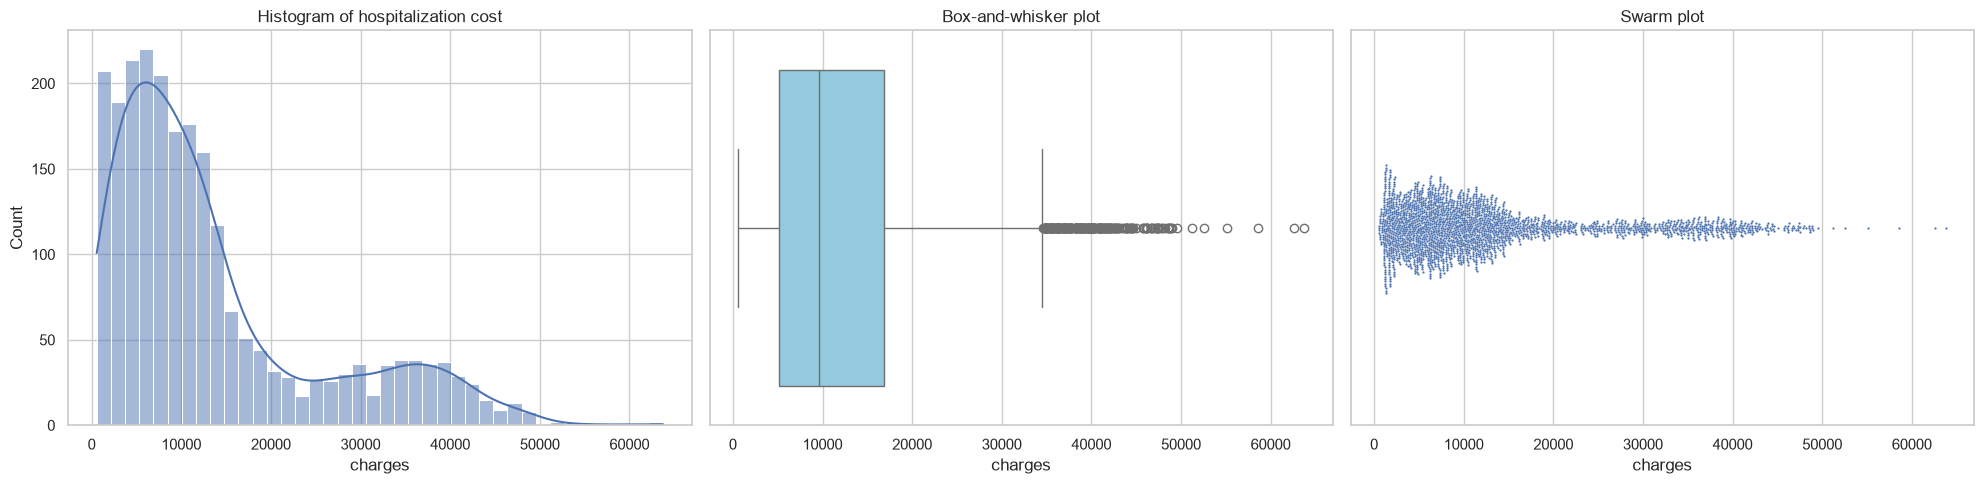

count     2325.0
mean     13521.7
std      11863.5
min        563.8
25%       5116.5
50%       9634.5
75%      16903.5
max      63770.4
Name: charges, dtype: float64

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.histplot(df["charges"], kde=True, ax=axes[0], bins=40); axes[0].set_title("Histogram of hospitalization cost")
sns.boxplot(x=df["charges"], ax=axes[1], color="skyblue"); axes[1].set_title("Box-and-whisker plot")
sns.swarmplot(x=df["charges"], ax=axes[2], size=1.6); axes[2].set_title("Swarm plot")
plt.tight_layout(); plt.show()
df["charges"].describe().round(1)

Costs are strongly **right-skewed**: most stays cost under ~15k, with a long tail up to ~63k (mostly smokers / severe cases).

### 10. Distribution across gender and hospital tiers

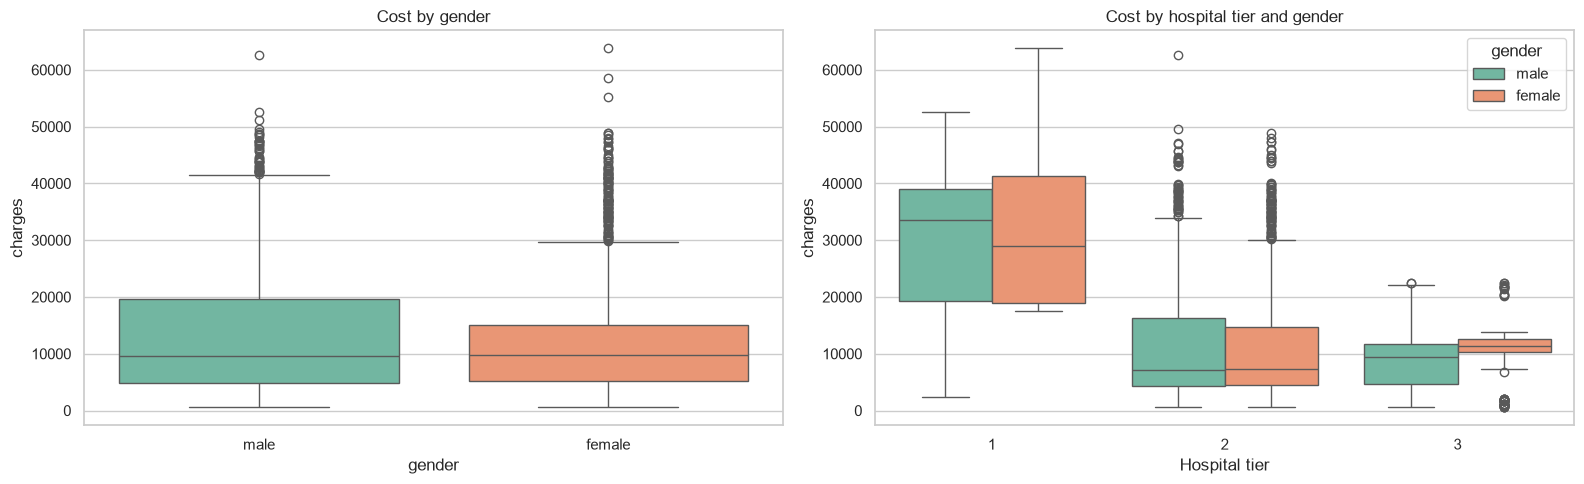

median              mean         
gender          female     male   female     male
Hospital tier                                    
1              28923.0  33476.0  30416.0  30004.0
2               7263.0   7137.0  11526.0  12365.0
3              11428.0   9391.0  10636.0   8637.0

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x="gender", y="charges", ax=axes[0], palette="Set2"); axes[0].set_title("Cost by gender")
sns.boxplot(data=df, x="Hospital tier", y="charges", hue="gender", ax=axes[1], palette="Set2"); axes[1].set_title("Cost by hospital tier and gender")
plt.tight_layout(); plt.show()
df.pivot_table(index="Hospital tier", columns="gender", values="charges", aggfunc=["median", "mean"]).round(0)

* **Gender:** distributions are very similar; mean costs differ by under 10% within each tier and there is no consistent direction.
* **Hospital tier:** **tier-1 (best) hospitals are far more expensive** (median ≈ 29-33k vs ≈ 7-11k) and have the widest spread,
  for both genders. Tiers 2 and 3 are similar to each other (tier 3's median is slightly higher, tier 2's mean slightly higher).

### 11. Radar chart — median cost per hospital tier

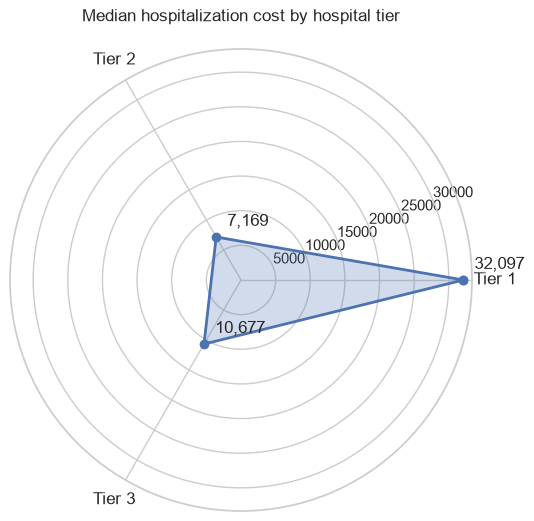

Hospital tier
1    32097.4
2     7168.8
3    10676.8
Name: charges, dtype: float64

In [12]:
med_tier = df.groupby("Hospital tier")["charges"].median()
labels = [f"Tier {t}" for t in med_tier.index]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
values = med_tier.tolist()
fig = plt.figure(figsize=(6, 6)); ax = plt.subplot(polar=True)
ax.plot(angles + angles[:1], values + values[:1], "o-", lw=2); ax.fill(angles + angles[:1], values + values[:1], alpha=0.25)
ax.set_xticks(angles); ax.set_xticklabels(labels, fontsize=12)
for a, v in zip(angles, values): ax.annotate(f"{v:,.0f}", (a, v), textcoords="offset points", xytext=(8, 8))
ax.set_title("Median hospitalization cost by hospital tier", pad=20); plt.show()
med_tier.round(1)

### 12. Frequency table & stacked bar chart — city tier × hospital tier

Hospital tier,1,2,3,Total
City tier,,,,
1,85,403,241,729
2,106,479,222,807
3,109,452,228,789
Total,300,1334,691,2325


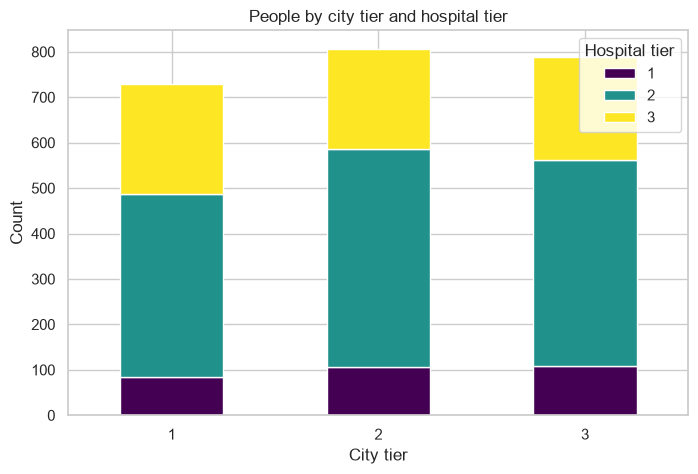

In [13]:
freq = pd.crosstab(df["City tier"], df["Hospital tier"], margins=True, margins_name="Total")
display(freq)
ax = pd.crosstab(df["City tier"], df["Hospital tier"]).plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
ax.set_title("People by city tier and hospital tier"); ax.set_xlabel("City tier"); ax.set_ylabel("Count"); ax.legend(title="Hospital tier")
plt.xticks(rotation=0); plt.show()

### 13. Hypothesis tests (α = 0.05)

In [14]:
ALPHA = 0.05
def show(name, stat, p):
    print(f"{name:65s} stat = {stat:9.3f}  p = {p:.3g}  -> {'REJECT H0' if p < ALPHA else 'fail to reject H0'}")

groups = [g["charges"] for _, g in df.groupby("Hospital tier")]
show("a. ANOVA: mean cost equal across 3 hospital tiers", *stats.f_oneway(*groups))
show("   (Kruskal-Wallis, non-parametric check)", *stats.kruskal(*groups))
groups = [g["charges"] for _, g in df.groupby("City tier")]
show("b. ANOVA: mean cost equal across 3 city tiers", *stats.f_oneway(*groups))
show("   (Kruskal-Wallis, non-parametric check)", *stats.kruskal(*groups))
show("c. Welch t-test: smokers vs non-smokers mean cost", *stats.ttest_ind(df.loc[df.smoker == 1, "charges"], df.loc[df.smoker == 0, "charges"], equal_var=False))
ct = pd.crosstab(df["smoker"], df["Heart Issues"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
show("d. Chi-square: smoking and heart issues are independent", chi2, p)
print("\nMean cost by city tier:", df.groupby("City tier")["charges"].mean().round(0).to_dict())
print("Mean cost smokers vs non-smokers:", df.groupby("smoker")["charges"].mean().round(0).to_dict())
ct

a. ANOVA: mean cost equal across 3 hospital tiers                 stat =   493.990  p = 1.77e-179  -> REJECT H0
   (Kruskal-Wallis, non-parametric check)                         stat =   456.599  p = 7.09e-100  -> REJECT H0
b. ANOVA: mean cost equal across 3 city tiers                     stat =     1.454  p = 0.234  -> fail to reject H0
   (Kruskal-Wallis, non-parametric check)                         stat =     1.539  p = 0.463  -> fail to reject H0
c. Welch t-test: smokers vs non-smokers mean cost                 stat =    56.317  p = 6.7e-238  -> REJECT H0
d. Chi-square: smoking and heart issues are independent           stat =     0.086  p = 0.769  -> fail to reject H0

Mean cost by city tier: {1: 13010.0, 2: 13472.0, 3: 14045.0}
Mean cost smokers vs non-smokers: {0: 8409.0, 1: 32867.0}


Heart Issues,0,1
smoker,,
0,1108,731
1,297,189


**Conclusions**
* **a.** Hospital tier matters — costs differ significantly between tiers (reject H0).
* **b.** City tier does **not** significantly change average cost (fail to reject H0).
* **c.** Smokers' average cost is several times higher than non-smokers' (reject H0) — the single biggest cost driver.
* **d.** No evidence of dependence between smoking and heart issues in this data (fail to reject H0).

## Week 2 — Machine learning
### 1. Correlation between predictors

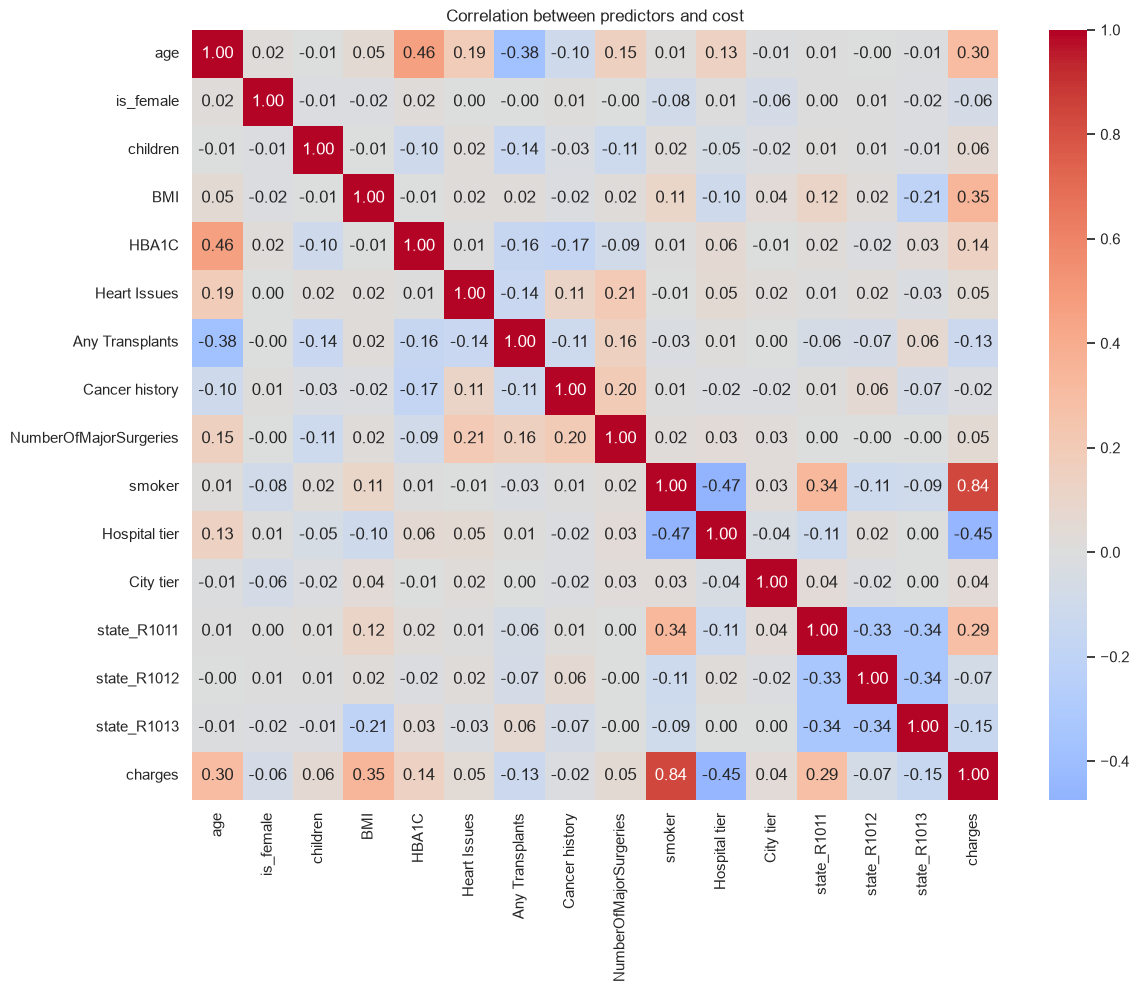

Most correlated predictor pairs:
 smoker       Hospital tier      0.474
age          HBA1C              0.460
             Any Transplants    0.382
state_R1011  state_R1013        0.341
state_R1012  state_R1013        0.340
dtype: float64


In [15]:
features = ["age", "is_female", "children", "BMI", "HBA1C", "Heart Issues", "Any Transplants", "Cancer history",
            "NumberOfMajorSurgeries", "smoker", "Hospital tier", "City tier", "state_R1011", "state_R1012", "state_R1013"]
plt.figure(figsize=(13, 10))
sns.heatmap(df[features + ["charges"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between predictors and cost"); plt.show()
corr = df[features].corr().abs()
high = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Most correlated predictor pairs:\n", high.head(5).round(3))

Predictors are at most moderately correlated with each other (largest pairs: smoker–hospital tier ≈ 0.47, age–HbA1c ≈ 0.46,
age–transplants ≈ 0.38), so multicollinearity is not a serious problem; Ridge regularisation handles what remains. **Smoker** is by far the strongest correlate of cost, followed by **hospital tier** (negative: tier 1 is costlier), **age** and **BMI**.

### 2. Regression models with stratified 5-fold CV, pipelines, standardisation, tuning and regularisation
Stratified K-fold needs classes, so the continuous target is **binned into cost quintiles** to stratify — each fold then contains the
full range of costs. A `fold` column records which fold each row belongs to.

In [16]:
X = df[features].astype(float)
y = df["charges"].values
cost_bins = pd.qcut(y, q=5, labels=False)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(X, cost_bins))
df["fold"] = -1
for i, (_, val_idx) in enumerate(folds):
    df.iloc[val_idx, df.columns.get_loc("fold")] = i
print(df.groupby("fold")["charges"].agg(["count", "mean", "median"]).round(0))

      count     mean   median
fold                         
0       465  13457.0   9284.0
1       465  13505.0   9749.0
2       465  13421.0   9361.0
3       465  13748.0  10118.0
4       465  13477.0   9836.0


In [17]:
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
def cv_summary(est, name):
    s = cross_validate(est, X, y, cv=folds, scoring=scoring, return_train_score=True)
    return {"model": name, "train_r2": s["train_r2"].mean(), "cv_r2": s["test_r2"].mean(),
            "cv_rmse": -s["test_rmse"].mean(), "cv_mae": -s["test_mae"].mean()}

lin = Pipeline([("scale", StandardScaler()), ("model", LinearRegression())])
ridge = Pipeline([("scale", StandardScaler()), ("model", Ridge())])
ridge_search = GridSearchCV(ridge, {"model__alpha": np.logspace(-3, 3, 25)}, cv=folds, scoring="neg_root_mean_squared_error")
ridge_search.fit(X, y)
print("Best Ridge alpha:", round(ridge_search.best_params_["model__alpha"], 4))
best_ridge = ridge_search.best_estimator_

# Costs are right-skewed: also try Ridge on log(cost) (predictions transformed back)
from sklearn.compose import TransformedTargetRegressor
log_ridge = TransformedTargetRegressor(regressor=Pipeline([("scale", StandardScaler()), ("model", Ridge())]), func=np.log, inverse_func=np.exp)
log_search = GridSearchCV(log_ridge, {"regressor__model__alpha": np.logspace(-3, 3, 25)}, cv=folds, scoring="neg_root_mean_squared_error").fit(X, y)

results = [cv_summary(lin, "Linear regression"), cv_summary(best_ridge, "Ridge (tuned)"),
           cv_summary(log_search.best_estimator_, "Ridge on log(cost)")]

Best Ridge alpha: 5.6234


### Gradient Boosting, variable importance and redundant variables

In [18]:
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)
gb_search = GridSearchCV(gb, {"n_estimators": [200, 400], "learning_rate": [0.03, 0.05, 0.1], "max_depth": [2, 3, 4], "subsample": [0.8, 1.0]},
                         cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X, y)
print("Best GB params:", gb_search.best_params_)
best_gb = gb_search.best_estimator_
results.append(cv_summary(best_gb, "Gradient Boosting (tuned)"))
res = pd.DataFrame(results).set_index("model").round(3)
res

Best GB params: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}


,train_r2,cv_r2,cv_rmse,cv_mae
model,,,,
Linear regression,0.860,0.858,4469.934,2744.066
Ridge (tuned),0.860,0.858,4469.765,2751.853
Ridge on log(cost),0.730,0.728,6170.370,3658.134
Gradient Boosting (tuned),0.948,0.916,3431.454,1970.778


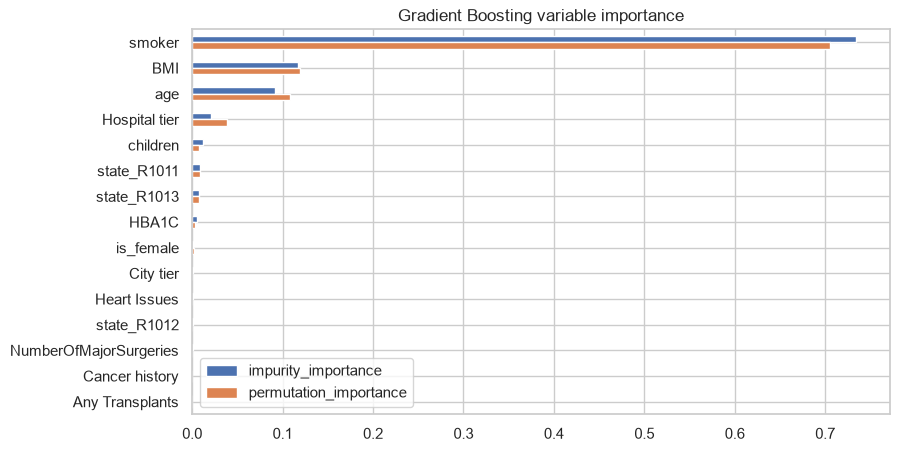

,impurity_importance,permutation_importance
smoker,0.7346,0.7055
BMI,0.1171,0.1197
age,0.0913,0.1077
Hospital tier,0.0206,0.0382
children,0.0116,0.0074
state_R1011,0.0085,0.0081
state_R1013,0.0071,0.0071
HBA1C,0.0057,0.0033
is_female,0.0014,0.0015
City tier,0.0005,0.0003


In [19]:
imp = pd.DataFrame({"impurity_importance": best_gb.feature_importances_}, index=features)
perm = permutation_importance(best_gb, X, y, n_repeats=10, random_state=RANDOM_STATE)
imp["permutation_importance"] = perm.importances_mean / perm.importances_mean.sum()
imp = imp.sort_values("impurity_importance", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
imp.plot.barh(ax=ax); ax.invert_yaxis(); ax.set_title("Gradient Boosting variable importance"); plt.show()
imp.round(4)

In [20]:
redundant = imp[imp["impurity_importance"] < 0.01].index.tolist()
print("Redundant variables (importance < 1%):", redundant)
coefs = pd.Series(best_ridge.named_steps["model"].coef_, index=features).sort_values(key=abs, ascending=False)
print("\nRidge standardized coefficients:\n", coefs.round(1))

Redundant variables (importance < 1%): ['state_R1011', 'state_R1013', 'HBA1C', 'is_female', 'City tier', 'Heart Issues', 'state_R1012', 'NumberOfMajorSurgeries', 'Cancer history', 'Any Transplants']

Ridge standardized coefficients:
 smoker                    9070.1
age                       3512.4
BMI                       2779.0
Hospital tier            -1191.8
children                   509.9
state_R1013               -504.9
state_R1011               -371.4
state_R1012               -212.1
HBA1C                      170.5
Any Transplants            146.1
Cancer history             113.3
NumberOfMajorSurgeries     -42.0
City tier                   28.1
is_female                   19.2
Heart Issues               -14.0
dtype: float64


**Findings:** cost is driven by **smoking** (≈ 73% of Gradient Boosting importance), **BMI** (≈ 12%), **age** (≈ 9%) and **hospital tier** (≈ 2%).
HbA1c, heart issues, surgeries, cancer history, transplants, gender, city tier and the state dummies each contribute < 1% and are **redundant**.
Gradient Boosting (CV R² ≈ 0.92, RMSE ≈ 3.4k) clearly beats linear/Ridge regression (CV R² ≈ 0.86, RMSE ≈ 4.5k) because it captures
non-linear interactions such as smoking × high BMI. Ridge barely changes the linear model (little overfitting: train R² ≈ CV R²).

### 3-4. Case scenario — Ms. Jayna Christopher

In [21]:
dob = pd.Timestamp("1988-12-28")
jayna = pd.DataFrame([{
    "age": int((REF_DATE - dob).days / 365.25), "is_female": 1, "children": 2,
    "BMI": round(85 / 1.70 ** 2, 2), "HBA1C": 5.8, "Heart Issues": 0, "Any Transplants": 0,
    "Cancer history": 1,              # father died of lung cancer
    "NumberOfMajorSurgeries": 0, "smoker": 1, "Hospital tier": 1, "City tier": 1,
    "state_R1011": 1, "state_R1012": 0, "state_R1013": 0}])[features]
display(jayna)

models_final = {"Ridge (tuned)": best_ridge.fit(X, y), "Ridge on log(cost)": log_search.best_estimator_.fit(X, y),
                "Gradient Boosting (tuned)": best_gb.fit(X, y)}
pred = {n: float(m.predict(jayna)[0]) for n, m in models_final.items()}
pred_df = pd.DataFrame({"predicted_cost": pred, "cv_rmse": res.loc[list(pred), "cv_rmse"]}).round(0)
display(pred_df)
print(f"Best model (lowest CV RMSE): {res['cv_rmse'].idxmin()} -> estimated hospitalization cost = {pred[res['cv_rmse'].idxmin()]:,.0f}")

,age,is_female,children,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,Hospital tier,City tier,state_R1011,state_R1012,state_R1013
0,37,1,2,29.41,5.8,0,0,1,0,1,1,1,1,0,0


,predicted_cost,cv_rmse
Ridge (tuned),31673.0,4470.0
Ridge on log(cost),23381.0,6170.0
Gradient Boosting (tuned),27081.0,3431.0


Best model (lowest CV RMSE): Gradient Boosting (tuned) -> estimated hospitalization cost = 27,081


Jayna (age 37, BMI ≈ 29.4, smoker, tier-1 hospital) falls in the high-cost group mainly because she **smokes** and will be treated in a
**tier-1 hospital**. The best model (Gradient Boosting) estimates her hospitalization cost at **≈ 27,000**; Ridge gives ≈ 31,700.

## Summary
* Smoking is the dominant cost factor (smokers cost ≈ 4× more on average); BMI, age and hospital tier follow.
* Hospital tier significantly affects cost, while city tier and gender do not.
* Gradient Boosting gives the best cross-validated accuracy; state dummies (beyond R1011-R1013), city tier, gender and transplants are largely redundant.